In [1]:
# -------------------------------------------------------------------
# Final L and interpolation diagnostics: environment, imports, metadata
# -------------------------------------------------------------------

# IMPORTANT:
# Run this cell from a fresh kernel, before importing WDM, jax,
# or WDM_LISAresponse modules.

import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_PLATFORM_NAME"] = "cpu"

# Verify JAX backend before importing WDM / response code
import jax

print("JAX devices:", jax.devices())
print("JAX default backend:", jax.default_backend())

if jax.default_backend() != "cpu":
    raise RuntimeError(
        "JAX is not using CPU. Restart the kernel and run this cell before any other imports."
    )

import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import WDM

from pathlib import Path

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits

from WDM_LISAresponse.code.lisa_response.TDI import gen2_michelson_wdm

from WDM_LISAresponse.code.utils.utils import (
    compute_wdm_cut_info,
    apply_wdm_cut,
    wdm_mismatch,
)

# -------------------------------------------------------------------
# Where saved TD reference lives
# -------------------------------------------------------------------

BASE_OUTPUT_DIR = Path("runs")  # change if your OUTPUT_DIR is elsewhere

# Search recursively for saved TD metadata files.
metadata_files = list(BASE_OUTPUT_DIR.rglob("td_reference_metadata_*.json"))

if len(metadata_files) == 0:
    raise FileNotFoundError(
        f"No td_reference_metadata_*.json files found under {BASE_OUTPUT_DIR.resolve()}"
    )

# Use newest metadata file by modification time
td_meta_path = max(metadata_files, key=lambda p: p.stat().st_mtime)

with open(td_meta_path, "r") as f:
    td_metadata = json.load(f)

TD_SAVE_DIR = td_meta_path.parent

print()
print("Using TD metadata:", td_meta_path)
print("TD save directory:", TD_SAVE_DIR)

# Quick metadata sanity check
print()
print("Metadata keys:", sorted(td_metadata.keys()))

if "saved_files" not in td_metadata:
    raise KeyError("Metadata file does not contain 'saved_files'.")

required_saved = ["td_xyz", "td_one_arm_links"]

for key in required_saved:
    if key not in td_metadata["saved_files"]:
        raise KeyError(f"Metadata saved_files does not contain required key: {key}")

print()
print("Saved TD arrays:", td_metadata["saved_files"]["td_xyz"])
print("Saved one-arm links:", td_metadata["saved_files"]["td_one_arm_links"])

# -------------------------------------------------------------------
# Sweep output directory
# -------------------------------------------------------------------

DELTA_T_SWEEP_DIR = TD_SAVE_DIR.parent / "deltaT_sensitivity_1yr"
DELTA_T_SWEEP_DIR.mkdir(parents=True, exist_ok=True)

FINAL_DIAG_DIR = DELTA_T_SWEEP_DIR / "final_L_interp_diagnostics"
FINAL_DIAG_DIR.mkdir(parents=True, exist_ok=True)

print()
print("DeltaT sweep directory:", DELTA_T_SWEEP_DIR)
print("Final diagnostics directory:", FINAL_DIAG_DIR)

JAX devices: [CpuDevice(id=0)]
JAX default backend: cpu

Using TD metadata: runs/emri_01yr_td_Nf500_dt10/td_reference/td_reference_metadata_lagblock_L25_R2048_B32_ip16_no_m0_20260612_163228.json
TD save directory: runs/emri_01yr_td_Nf500_dt10/td_reference

Metadata keys: ['N_original', 'N_padded', 'alpha', 'array_shapes', 'compressed_npz', 'created_at', 'dt', 'duration_yr', 'method_label', 'pad_info', 'run_name', 'saved_files', 'td_runtime_seconds', 'td_settings', 'tukey_factor', 'wdm_settings_for_later_comparison']

Saved TD arrays: runs/emri_01yr_td_Nf500_dt10/td_reference/td_xyz_lagblock_L25_R2048_B32_ip16_no_m0_20260612_163228.npz
Saved one-arm links: runs/emri_01yr_td_Nf500_dt10/td_reference/td_one_arm_links_lagblock_L25_R2048_B32_ip16_no_m0_20260612_163228.npz

DeltaT sweep directory: runs/emri_01yr_td_Nf500_dt10/deltaT_sensitivity_1yr
Final diagnostics directory: runs/emri_01yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics


In [2]:
# -------------------------------------------------------------------
# Inspect available TD reference metadata files and select the intended run
# -------------------------------------------------------------------

metadata_rows = []

for path in sorted(metadata_files):
    try:
        with open(path, "r") as f:
            meta = json.load(f)

        metadata_rows.append(
            {
                "path": str(path),
                "run_name": meta.get("run_name", ""),
                "duration_yr": meta.get("duration_yr", np.nan),
                "dt": meta.get("dt", np.nan),
                "N_original": meta.get("N_original", np.nan),
                "N_padded": meta.get("N_padded", np.nan),
                "method_label": meta.get("method_label", ""),
                "modified_time": path.stat().st_mtime,
            }
        )
    except Exception as exc:
        metadata_rows.append(
            {
                "path": str(path),
                "run_name": "<could not read>",
                "duration_yr": np.nan,
                "dt": np.nan,
                "N_original": np.nan,
                "N_padded": np.nan,
                "method_label": str(exc),
                "modified_time": path.stat().st_mtime,
            }
        )

df_metadata_candidates = pd.DataFrame(metadata_rows)
df_metadata_candidates = df_metadata_candidates.sort_values(
    ["duration_yr", "modified_time"],
    ascending=[False, False],
).reset_index(drop=True)

display(
    df_metadata_candidates[
        [
            "duration_yr",
            "dt",
            "N_original",
            "N_padded",
            "run_name",
            "method_label",
            "path",
        ]
    ]
)

# Prefer the longest available duration, unless you manually override below.
selected_index = 0

td_meta_path = Path(df_metadata_candidates.loc[selected_index, "path"])

with open(td_meta_path, "r") as f:
    td_metadata = json.load(f)

TD_SAVE_DIR = td_meta_path.parent

print()
print("Selected TD metadata:")
print(" ", td_meta_path)
print()
print("duration_yr:", td_metadata.get("duration_yr"))
print("N_original:", td_metadata.get("N_original"))
print("N_padded:", td_metadata.get("N_padded"))
print("dt:", td_metadata.get("dt"))
print("run_name:", td_metadata.get("run_name"))
print("method_label:", td_metadata.get("method_label"))

DELTA_T_SWEEP_DIR = TD_SAVE_DIR.parent / "deltaT_sensitivity_1yr"
DELTA_T_SWEEP_DIR.mkdir(parents=True, exist_ok=True)

FINAL_DIAG_DIR = DELTA_T_SWEEP_DIR / "final_L_interp_diagnostics"
FINAL_DIAG_DIR.mkdir(parents=True, exist_ok=True)

print()
print("TD save directory:", TD_SAVE_DIR)
print("Final diagnostics directory:", FINAL_DIAG_DIR)

,duration_yr,dt,N_original,N_padded,run_name,method_label,path
0,1.0,10.0,3155814,3219000,emri_1yr_td_Nf500_dt10,lagblock_L25_R2048_B32_ip16_no_m0,runs/emri_1yr_td_Nf500_dt10/td_reference/td_re...
1,0.1,10.0,315581,322000,emri_01yr_td_Nf500_dt10,lagblock_L25_R2048_B32_ip16_no_m0,runs/emri_01yr_td_Nf500_dt10/td_reference/td_r...



Selected TD metadata:
  runs/emri_1yr_td_Nf500_dt10/td_reference/td_reference_metadata_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.json

duration_yr: 1.0
N_original: 3155814
N_padded: 3219000
dt: 10.0
run_name: emri_1yr_td_Nf500_dt10
method_label: lagblock_L25_R2048_B32_ip16_no_m0

TD save directory: runs/emri_1yr_td_Nf500_dt10/td_reference
Final diagnostics directory: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics


In [3]:
# -------------------------------------------------------------------
# Load saved 1-year TD reference arrays and remove old Nf=500 WDM-tail padding
# -------------------------------------------------------------------

saved_files = td_metadata["saved_files"]

td_arrays_path = Path(saved_files["td_xyz"])
td_links_path = Path(saved_files["td_one_arm_links"])

# Fall back to TD_SAVE_DIR if paths were saved relative to another environment.
if not td_arrays_path.exists():
    td_arrays_path = TD_SAVE_DIR / td_arrays_path.name

if not td_links_path.exists():
    td_links_path = TD_SAVE_DIR / td_links_path.name

if not td_arrays_path.exists():
    raise FileNotFoundError(f"Could not find TD arrays file: {td_arrays_path}")

if not td_links_path.exists():
    raise FileNotFoundError(f"Could not find TD one-arm links file: {td_links_path}")

print("Loading TD arrays from:", td_arrays_path)
print("Loading TD one-arm links from:", td_links_path)

td_arrays = np.load(td_arrays_path, allow_pickle=False)
td_links = np.load(td_links_path, allow_pickle=False)

print()
print("TD array keys:", td_arrays.files)
print("TD link keys:", td_links.files)

# Main TD arrays
times_pad = td_arrays["times_pad"]
hplus_td = td_arrays["hplus_td"]
hcross_td = td_arrays["hcross_td"]

X_td = td_arrays["X_td"]
Y_td = td_arrays["Y_td"]
Z_td = td_arrays["Z_td"]

# One-arm diagnostic link
if "dl_12" not in td_links.files:
    raise KeyError("dl_12 was not found in the saved one-arm link file.")

dl_12_td = td_links["dl_12"]

dt = float(times_pad[1] - times_pad[0])

print()
print("Loaded saved shapes:")
print("  times_pad:", times_pad.shape)
print("  hplus_td: ", hplus_td.shape)
print("  hcross_td:", hcross_td.shape)
print("  X_td:     ", X_td.shape)
print("  Y_td:     ", Y_td.shape)
print("  Z_td:     ", Z_td.shape)
print("  dl_12_td: ", dl_12_td.shape)

print()
print("dt:", dt)
print("Saved padded length:", len(times_pad))

# -------------------------------------------------------------------
# Remove the old saved Nf=500 WDM-tail padding
# -------------------------------------------------------------------

def get_pad_info_value(pad_info, metadata, key, default=None):
    if key in pad_info:
        return pad_info[key]
    if key in metadata:
        return metadata[key]
    return default


pad_info = td_metadata.get("pad_info", {})

original_length_value = get_pad_info_value(
    pad_info,
    td_metadata,
    "original_length",
    default=None,
)

if original_length_value is None:
    raise KeyError("Could not find original_length in td_metadata or pad_info.")

original_length = int(original_length_value)

if "window_pad_left" not in pad_info or "window_pad_right" not in pad_info:
    raise KeyError("Expected window_pad_left and window_pad_right in td_metadata['pad_info'].")

window_pad_left = int(pad_info["window_pad_left"])
window_pad_right = int(pad_info["window_pad_right"])

# Clean base length:
# original physical signal + left/right window padding,
# but before the old Nf=500 WDM-tail padding.
post_window_length = original_length + window_pad_left + window_pad_right

old_saved_tail_right = len(times_pad) - post_window_length

if old_saved_tail_right < 0:
    raise ValueError(
        "Loaded TD arrays are shorter than original_length + window padding.\n"
        f"  len(times_pad)={len(times_pad)}\n"
        f"  post_window_length={post_window_length}"
    )

base_slice = slice(0, post_window_length)

times_base = times_pad[base_slice]
hplus_base = hplus_td[base_slice]
hcross_base = hcross_td[base_slice]

X_td_base = X_td[base_slice]
Y_td_base = Y_td[base_slice]
Z_td_base = Z_td[base_slice]

dl_12_td_base = dl_12_td[base_slice]

dt = float(times_base[1] - times_base[0])

print()
print("Saved TD length:              ", len(times_pad))
print("Original physical length:     ", original_length)
print("Window pad left:              ", window_pad_left)
print("Window pad right:             ", window_pad_right)
print("Post-window base length:      ", post_window_length)
print("Old saved WDM tail removed:   ", old_saved_tail_right)

print()
print("Base array shapes:")
print("  times_base:    ", times_base.shape)
print("  hplus_base:    ", hplus_base.shape)
print("  hcross_base:   ", hcross_base.shape)
print("  X_td_base:     ", X_td_base.shape)
print("  Y_td_base:     ", Y_td_base.shape)
print("  Z_td_base:     ", Z_td_base.shape)
print("  dl_12_td_base: ", dl_12_td_base.shape)

duration_years_base = original_length * dt / (365.25 * 24 * 3600)

print()
print("Physical duration years:", duration_years_base)

if not (0.9 < duration_years_base < 1.1):
    raise RuntimeError(
        "This does not look like the one-year reference. "
        f"duration_years_base={duration_years_base}"
    )

Loading TD arrays from: runs/emri_1yr_td_Nf500_dt10/td_reference/td_xyz_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.npz
Loading TD one-arm links from: runs/emri_1yr_td_Nf500_dt10/td_reference/td_one_arm_links_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.npz

TD array keys: ['times_pad', 'hplus_td', 'hcross_td', 'X_td', 'Y_td', 'Z_td']
TD link keys: ['times_pad', 'dl_21', 'dl_32', 'dl_13', 'dl_31', 'dl_23', 'dl_12']

Loaded saved shapes:
  times_pad: (3219000,)
  hplus_td:  (3219000,)
  hcross_td: (3219000,)
  X_td:      (3219000,)
  Y_td:      (3219000,)
  Z_td:      (3219000,)
  dl_12_td:  (3219000,)

dt: 10.0
Saved padded length: 3219000

Saved TD length:               3219000
Original physical length:      3155814
Window pad left:               31559
Window pad right:              31559
Post-window base length:       3218932
Old saved WDM tail removed:    68

Base array shapes:
  times_base:     (3218932,)
  hplus_base:     (3218932,)
  hcross_base:    (3218932,)
  X_td_b

In [4]:
# -------------------------------------------------------------------
# Load orbit/source parameters and core WDM response settings
# -------------------------------------------------------------------

# The TD metadata does not store theta/phi in this saved run.
# Use the same defaults as the old DeltaT notebook.
theta = float(td_metadata.get("theta", np.pi / 2))
phi = float(td_metadata.get("phi", 0.0))

print("Source location:")
print("  theta =", theta)
print("  phi   =", phi)

# -------------------------------------------------------------------
# Orbit file
# -------------------------------------------------------------------

ORBIT_FILE = Path("esa-trailing-orbits.h5")

if not ORBIT_FILE.exists():
    # Search a few likely locations.
    orbit_candidates = []

    for root in [Path.cwd(), Path("runs"), Path("/mnt/data")]:
        if root.exists():
            orbit_candidates.extend(root.rglob("esa-trailing-orbits.h5"))

    if len(orbit_candidates) == 0:
        raise FileNotFoundError(
            "Could not find esa-trailing-orbits.h5.\n"
            "Set ORBIT_FILE manually before continuing, e.g.\n"
            "    ORBIT_FILE = Path('/path/to/esa-trailing-orbits.h5')"
        )

    ORBIT_FILE = orbit_candidates[0]

print()
print("Using orbit file:")
print(" ", ORBIT_FILE.resolve())

orbit_data = read_orbit_file(str(ORBIT_FILE))
orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)

orbits_trailing = InterpolatedOrbits(
    orbit_times,
    orbit_data.positions,
    orbit_data.velocities,
)

# Alias used by some newer cells
orbits = orbits_trailing

print()
print("Loaded trailing LISA orbits.")
print("  orbit_data.size:", orbit_data.size)
print("  orbit_data.dt:  ", orbit_data.dt)

# -------------------------------------------------------------------
# WDM / response settings
# -------------------------------------------------------------------

wdm_settings_saved = td_metadata.get("wdm_settings_for_later_comparison", {})

# Keep the validated/default WDM basis settings
d = int(wdm_settings_saved.get("d", 4))
A_frac = float(wdm_settings_saved.get("A_frac", 0.25))

# In the validated no-m0 path this is fixed.
CALC_M0 = bool(wdm_settings_saved.get("calc_m0", False))

# For these diagnostic sweeps, keep q fixed as in the DeltaT sweep.
# The old notebook used q_wdm = 1 for all Nf.
q_wdm = 1

# Baseline settings
Nf_final = 100
L_baseline = int(wdm_settings_saved.get("L_trunc_value", 25))
interp_points_baseline = 16

MISMATCH_TIMING_THRESHOLD = 5e-5

FAST_TDI_ASSEMBLY_MODE = "batch_map"

print()
print("Core WDM / response settings:")
print("  d:                      ", d)
print("  A_frac:                 ", A_frac)
print("  q_wdm:                  ", q_wdm)
print("  calc_m0:                ", CALC_M0)
print("  Nf_final:               ", Nf_final)
print("  L_baseline:             ", L_baseline)
print("  interp_points_baseline: ", interp_points_baseline)
print("  timing mismatch limit:  ", MISMATCH_TIMING_THRESHOLD)
print("  TDI assembly mode:      ", FAST_TDI_ASSEMBLY_MODE)

Source location:
  theta = 1.5707963267948966
  phi   = 0.0

Using orbit file:
  /data/tk593/LISA_Response/LISAresponse/WDM_LISAresponse/examples/esa-trailing-orbits.h5

Loaded trailing LISA orbits.
  orbit_data.size: 1721
  orbit_data.dt:   161789.95624780655

Core WDM / response settings:
  d:                       4
  A_frac:                  0.25
  q_wdm:                   1
  calc_m0:                 False
  Nf_final:                100
  L_baseline:              25
  interp_points_baseline:  16
  timing mismatch limit:   5e-05
  TDI assembly mode:       batch_map


In [5]:
# -------------------------------------------------------------------
# Helper functions for final L / interpolation diagnostics
# -------------------------------------------------------------------

import gc
import importlib
import WDM.code.time_delay_filters.time_shift_fast as tsf

from WDM_LISAresponse.code.utils.utils import wdm_tail_padding_info
from WDM_LISAresponse.code.lisa_response.TDI import (
    precompute_gen2_michelson_wdm_geometry,
    precompute_gen2_michelson_wdm_waveform,
    gen2_michelson_wdm_from_waveform_precomputed,
)

# Reload in case the patched WDM_GW_wavelets time-shift module changed.
tsf = importlib.reload(tsf)


def clear_jax_memory():
    gc.collect()

    try:
        import jax
        if hasattr(jax, "clear_caches"):
            jax.clear_caches()
    except Exception:
        pass

    try:
        for name in ["_KERNEL_WDM_CACHE", "_KERNEL_PRECOMP_CACHE", "_CNM_PARITY_CACHE"]:
            cache = getattr(tsf, name, None)
            if hasattr(cache, "clear"):
                cache.clear()
    except Exception:
        pass


def wdm_target_length(n_samples, Nf):
    info = wdm_tail_padding_info(int(n_samples), int(Nf))
    return int(info["target_length"])


def pad_right_to_length(x, target_length):
    x = np.asarray(x)
    target_length = int(target_length)

    if x.shape[0] > target_length:
        raise ValueError(f"Array length {x.shape[0]} exceeds target length {target_length}.")

    if x.shape[0] == target_length:
        return x.copy()

    pad_right = target_length - x.shape[0]
    return np.pad(x, (0, pad_right), mode="constant")


def make_wdm_cut_slices(Nf, target_length):
    """
    Conservative row cut matching the window + zero-padding logic.

    We cut:
    - physical Tukey taper half-width
    - explicit zero padding added around the tapered signal
    - extra WDM tail padding on the right
    """
    Nf = int(Nf)
    target_length = int(target_length)

    alpha = float(td_metadata.get("alpha", 0.0))
    original_length = int(td_metadata.get("N_original", len(times_base)))

    pad_info = td_metadata.get("pad_info", {})
    window_pad_left = int(pad_info.get("window_pad_left", 0))
    window_pad_right = int(pad_info.get("window_pad_right", 0))

    taper_half = int(np.ceil(alpha * original_length / 2.0))

    tail_right = int(target_length - len(times_base))
    if tail_right < 0:
        raise ValueError("target_length is shorter than times_base.")

    n_left_cut = int(np.ceil((taper_half + window_pad_left) / Nf))
    n_right_cut = int(np.ceil((taper_half + window_pad_right + tail_right) / Nf))

    return {
        "n_left_cut": n_left_cut,
        "n_right_cut": n_right_cut,
        "tail_right": tail_right,
        "taper_half": taper_half,
        "window_pad_left": window_pad_left,
        "window_pad_right": window_pad_right,
    }


def cut_wdm_rows(arr, cut_info):
    left = int(cut_info["n_left_cut"])
    right = int(cut_info["n_right_cut"])

    if right == 0:
        return arr[left:, :]

    return arr[left:-right, :]


def make_td_reference_wdm_arrays(Nf_value, *, d_value=None, A_frac_value=None):
    """
    Transform saved TD reference arrays to the WDM grid for this Nf.
    """
    Nf_value = int(Nf_value)
    d_value = d if d_value is None else int(d_value)
    A_frac_value = A_frac if A_frac_value is None else float(A_frac_value)

    target_length = wdm_target_length(len(times_base), Nf_value)

    X_pad = pad_right_to_length(X_td_base, target_length)
    Y_pad = pad_right_to_length(Y_td_base, target_length)
    Z_pad = pad_right_to_length(Z_td_base, target_length)
    dl12_pad = pad_right_to_length(dl_12_td_base, target_length)

    wdm_ref = WDM.WDM.WDM_transform(
        dt=dt,
        Nf=Nf_value,
        N=target_length,
        q=q_wdm,
        calc_m0=CALC_M0,
        d=d_value,
        A_frac=A_frac_value,
    )

    return {
        "wdm": wdm_ref,
        "target_length": target_length,
        "cut_info": make_wdm_cut_slices(Nf_value, target_length),
        "X_ref": wdm_ref.dwt(X_pad),
        "Y_ref": wdm_ref.dwt(Y_pad),
        "Z_ref": wdm_ref.dwt(Z_pad),
        "dl12_ref": wdm_ref.dwt(dl12_pad),
    }


def make_variable_shift_kwargs(*, interp_points):
    """
    Validated fast configuration, with variable interpolation-point count.
    """
    return {
        "assembly_backend": "lagfirst_chunked_lagblock",
        "assembly_precision": "complex64",
        "row_chunk_size": 2048,
        "lag_block_size": 32,
        "batch_chunk": 1,
        "tl_tp_mode": "interp",
        "tl_tp_interp_points": int(interp_points),
        "tl_tp_interp_pad": 0.0,
        "tl_tp_interp_kind": "linear",
        "tl_tp_interp_backend": "numpy",
    }


def block_until_ready_tree(obj):
    """
    Ensure JAX computations finish before timing stops.
    """
    if isinstance(obj, (list, tuple)):
        for item in obj:
            block_until_ready_tree(item)
        return

    if isinstance(obj, dict):
        for item in obj.values():
            block_until_ready_tree(item)
        return

    if hasattr(obj, "block_until_ready"):
        obj.block_until_ready()


print("Helper functions ready.")

Helper functions ready.


In [6]:
# -------------------------------------------------------------------
# Accuracy helper: run one direct WDM case and compare to TD-WDM reference
# -------------------------------------------------------------------

def mismatch_scalar(a, b):
    """
    Return scalar mismatch even if wdm_mismatch returns a tuple such as
    (mismatch, raw_overlap).
    """
    out = wdm_mismatch(a, b)

    if isinstance(out, tuple):
        out = out[1]

    return float(np.asarray(out))


def run_final_accuracy_case(
    *,
    Nf_value,
    L_value,
    interp_points,
    d_value=None,
    A_frac_value=None,
):
    Nf_value = int(Nf_value)
    L_value = int(L_value)
    interp_points = int(interp_points)

    d_value = d if d_value is None else int(d_value)
    A_frac_value = A_frac if A_frac_value is None else float(A_frac_value)

    print()
    print("=" * 90)
    print(
        f"Accuracy case: Nf={Nf_value}, L={L_value}, "
        f"interp_points={interp_points}, d={d_value}, A_frac={A_frac_value}"
    )
    print("=" * 90)

    clear_jax_memory()

    ref = make_td_reference_wdm_arrays(
        Nf_value,
        d_value=d_value,
        A_frac_value=A_frac_value,
    )

    shift_kwargs = make_variable_shift_kwargs(interp_points=interp_points)

    geom_precomp = precompute_gen2_michelson_wdm_geometry(
        times_base,
        theta,
        phi,
        orbits,
        Nf=Nf_value,
        L_trunc=L_value,
        q=q_wdm,
        d=d_value,
        A_frac=A_frac_value,
        calc_m0=CALC_M0,
        use_jax=True,
        variable_shift_kwargs=shift_kwargs,
    )

    wave_precomp = precompute_gen2_michelson_wdm_waveform(
        geom_precomp,
        hplus_base,
        hcross_base,
        variable_shift_kwargs=shift_kwargs,
        one_arm_cache=None,
    )

    X_wdm, Y_wdm, Z_wdm = gen2_michelson_wdm_from_waveform_precomputed(
        wave_precomp,
        variable_shift_kwargs=shift_kwargs,
        L_trunc=L_value,
        Nf=Nf_value,
        use_jax=True,
        tdi_assembly_mode=FAST_TDI_ASSEMBLY_MODE,
    )

    link_w = wave_precomp["link_w"]
    dl12_wdm = link_w[(1, 2)]

    cut_info = ref["cut_info"]

    X_mismatch_cut = mismatch_scalar(
        cut_wdm_rows(X_wdm, cut_info),
        cut_wdm_rows(ref["X_ref"], cut_info),
    )

    Y_mismatch_cut = mismatch_scalar(
        cut_wdm_rows(Y_wdm, cut_info),
        cut_wdm_rows(ref["Y_ref"], cut_info),
    )

    Z_mismatch_cut = mismatch_scalar(
        cut_wdm_rows(Z_wdm, cut_info),
        cut_wdm_rows(ref["Z_ref"], cut_info),
    )

    link_12_mismatch_cut = mismatch_scalar(
        cut_wdm_rows(dl12_wdm, cut_info),
        cut_wdm_rows(ref["dl12_ref"], cut_info),
    )

    max_mismatch_cut = float(
        np.nanmax(
            [
                X_mismatch_cut,
                Y_mismatch_cut,
                Z_mismatch_cut,
                link_12_mismatch_cut,
            ]
        )
    )

    row = {
        "Nf": Nf_value,
        "DeltaT": float(Nf_value * dt),
        "L_trunc": L_value,
        "interp_points": interp_points,
        "d": int(d_value),
        "A_frac": float(A_frac_value),
        "target_length": int(ref["target_length"]),
        "Nt": int(ref["wdm"].Nt),
        "n_left_cut": int(cut_info["n_left_cut"]),
        "n_right_cut": int(cut_info["n_right_cut"]),
        "tail_right": int(cut_info["tail_right"]),
        "X_mismatch_cut": X_mismatch_cut,
        "Y_mismatch_cut": Y_mismatch_cut,
        "Z_mismatch_cut": Z_mismatch_cut,
        "link_12_mismatch_cut": link_12_mismatch_cut,
        "max_mismatch_cut": max_mismatch_cut,
    }

    print("X mismatch:       ", X_mismatch_cut)
    print("Y mismatch:       ", Y_mismatch_cut)
    print("Z mismatch:       ", Z_mismatch_cut)
    print("link 12 mismatch: ", link_12_mismatch_cut)
    print("max mismatch:     ", max_mismatch_cut)

    return row


print("Accuracy helper ready.")

Accuracy helper ready.


In [10]:
# -------------------------------------------------------------------
# Final plot 1 data: L vs mismatch
# -------------------------------------------------------------------

L_accuracy_grid = [1, 2, 4, 6, 8, 10, 12, 15, 20, 25, 35, 50, 75]

L_mismatch_partial_path = (
    FINAL_DIAG_DIR
    / f"L_vs_mismatch_Nf{Nf_final}_ip{interp_points_baseline}_partial.csv"
)

L_mismatch_final_path = (
    FINAL_DIAG_DIR
    / f"L_vs_mismatch_Nf{Nf_final}_ip{interp_points_baseline}_full.csv"
)

# Fresh run
for path in [L_mismatch_partial_path, L_mismatch_final_path]:
    if path.exists():
        path.unlink()
        print("Removed old file:", path)

L_mismatch_results = []

for L_value in L_accuracy_grid:
    row = run_final_accuracy_case(
        Nf_value=Nf_final,
        L_value=L_value,
        interp_points=interp_points_baseline,
        d_value=d,
        A_frac_value=A_frac,
    )

    L_mismatch_results.append(row)

    df_L_mismatch = pd.DataFrame(L_mismatch_results)
    df_L_mismatch = df_L_mismatch.sort_values("L_trunc").reset_index(drop=True)
    df_L_mismatch.to_csv(L_mismatch_partial_path, index=False)

    print("Saved partial L mismatch sweep to:", L_mismatch_partial_path)

df_L_mismatch = pd.DataFrame(L_mismatch_results)
df_L_mismatch = df_L_mismatch.sort_values("L_trunc").reset_index(drop=True)
df_L_mismatch.to_csv(L_mismatch_final_path, index=False)

print()
print("Saved final L mismatch sweep to:", L_mismatch_final_path)

display(
    df_L_mismatch[
        [
            "L_trunc",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
            "max_mismatch_cut",
        ]
    ]
)

Removed old file: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_mismatch_Nf100_ip16_partial.csv

Accuracy case: Nf=100, L=1, interp_points=16, d=4, A_frac=0.25
X mismatch:        0.1207929007478093
Y mismatch:        0.12099207662558867
Z mismatch:        0.1104508367572222
link 12 mismatch:  0.11305412273012747
max mismatch:      0.12099207662558867
Saved partial L mismatch sweep to: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_mismatch_Nf100_ip16_partial.csv

Accuracy case: Nf=100, L=2, interp_points=16, d=4, A_frac=0.25
X mismatch:        0.09129809709070999
Y mismatch:        0.09743141114841378
Z mismatch:        0.08862302606412487
link 12 mismatch:  0.04999594856856121
max mismatch:      0.09743141114841378
Saved partial L mismatch sweep to: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_mismatch_Nf100_ip16_partial.csv

Accuracy case: Nf=100, L=4, interp_points=16, d=4,

,L_trunc,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut,max_mismatch_cut
0,1,0.120793,0.120992,0.110451,0.113054,0.120992
1,2,0.091298,0.097431,0.088623,0.049996,0.097431
2,4,0.027053,0.027720,0.026399,0.012349,0.027720
3,6,0.005860,0.005971,0.005748,0.002562,0.005971
4,8,0.000983,0.000971,0.000962,0.000433,0.000983
5,10,0.000129,0.000128,0.000129,0.000053,0.000129
6,12,0.000015,0.000016,0.000015,0.000007,0.000016
7,15,0.000002,0.000002,0.000002,0.000002,0.000002
8,20,0.000001,0.000002,0.000002,0.000001,0.000002
9,25,0.000001,0.000002,0.000002,0.000001,0.000002


Saved plot to:
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_mismatch_clean_Nf100_ip16.pdf
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_mismatch_clean_Nf100_ip16.png


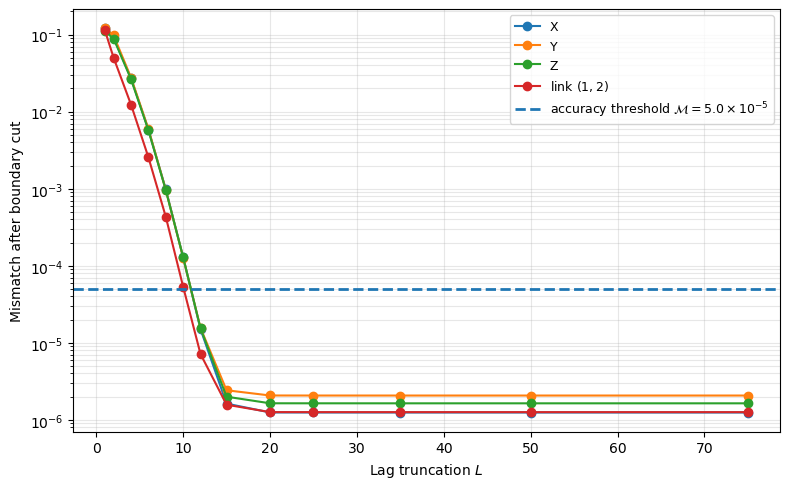

In [7]:
# -------------------------------------------------------------------
# Clean L-vs-mismatch plot with accuracy threshold line
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

L_mismatch_final_path = (
    FINAL_DIAG_DIR
    / f"L_vs_mismatch_Nf{Nf_final}_ip{interp_points_baseline}_full.csv"
)

if "df_L_mismatch" not in globals():
    df_L_mismatch = pd.read_csv(L_mismatch_final_path)

df_plot = df_L_mismatch.copy()
df_plot = df_plot.sort_values("L_trunc").reset_index(drop=True)

channels = {
    "X": "X_mismatch_cut",
    "Y": "Y_mismatch_cut",
    "Z": "Z_mismatch_cut",
    r"link $(1,2)$": "link_12_mismatch_cut",
}

fig, ax = plt.subplots(figsize=(8, 5))

for label, col in channels.items():
    if col not in df_plot.columns:
        print(f"Skipping {label}: column {col} not found.")
        continue

    mask = (
        np.isfinite(df_plot["L_trunc"].to_numpy(dtype=float))
        & np.isfinite(df_plot[col].to_numpy(dtype=float))
        & (df_plot["L_trunc"].to_numpy(dtype=float) > 0)
        & (df_plot[col].to_numpy(dtype=float) > 0)
    )

    d_plot = df_plot.loc[mask, ["L_trunc", col]].copy()

    if len(d_plot) == 0:
        continue

    ax.semilogy(
        d_plot["L_trunc"],
        d_plot[col],
        marker="o",
        label=label,
    )

# -------------------------------------------------------------------
# Accuracy threshold line
# -------------------------------------------------------------------

ax.axhline(
    MISMATCH_TIMING_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=r"accuracy threshold $\mathcal{{M}}={5.0 \times 10^{-5} }$",
)

# -------------------------------------------------------------------
# Formatting
# -------------------------------------------------------------------

ax.set_xlabel(r"Lag truncation $L$")
ax.set_ylabel("Mismatch after boundary cut")

ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)

fig.tight_layout()

plot_path_pdf = FINAL_DIAG_DIR / f"L_vs_mismatch_clean_Nf{Nf_final}_ip{interp_points_baseline}.pdf"
plot_path_png = FINAL_DIAG_DIR / f"L_vs_mismatch_clean_Nf{Nf_final}_ip{interp_points_baseline}.png"

fig.savefig(plot_path_pdf, bbox_inches="tight")
fig.savefig(plot_path_png, dpi=300, bbox_inches="tight")

print("Saved plot to:")
print(" ", plot_path_pdf)
print(" ", plot_path_png)

plt.show()

In [8]:
def make_variable_shift_kwargs_L_scaling(*, interp_points, batch_chunk=1):
    """
    Diagnostic L-scaling configuration.

    This avoids the lag-block boundary at 2L+1 = lag_block_size.
    It is intended for L-runtime scaling diagnostics, not for the final
    production timing baseline.
    """
    return {
        "assembly_backend": "lagfirst_chunked",
        "assembly_precision": "complex64",
        "row_chunk_size": 2048,
        "batch_chunk": int(batch_chunk),
        "tl_tp_mode": "interp",
        "tl_tp_interp_points": int(interp_points),
        "tl_tp_interp_pad": 0.0,
        "tl_tp_interp_kind": "linear",
        "tl_tp_interp_backend": "numpy",
    }

In [9]:
# -------------------------------------------------------------------
# Runtime helper: L timing using A0/A1/B structure
# -------------------------------------------------------------------

import gc
import time
import numpy as np
import pandas as pd
from pathlib import Path

from WDM_LISAresponse.code.lisa_response.TDI import (
    precompute_gen2_michelson_wdm_geometry,
    precompute_gen2_michelson_wdm_waveform,
    gen2_michelson_wdm_from_waveform_precomputed,
)

# Keep production-style timing by default: no shift-profile overhead.
A0_GEOM_WARM_RUNS = 1
A0_GEOM_REPEAT = 1

A1_WAVE_WARM_RUNS = 1
A1_WAVE_REPEAT = 5

B_TDI_WARM_RUNS = 1
B_TDI_REPEAT = 5

PROFILE_SHIFT_STAGES = False
RETURN_SHIFT_PROFILE = False
TIMING_ACCUMULATOR_CHUNK = 1


def time_call_stats(fn, *, warm=1, repeat=5):
    """
    Run fn with warm-up calls, then repeated measured calls.
    Returns final output and timing summary.
    """
    out = None

    for _ in range(int(warm)):
        out = fn()
        block_until_ready_tree(out)

    times_s = []

    for _ in range(int(repeat)):
        t0 = time.perf_counter()
        out = fn()
        block_until_ready_tree(out)
        t1 = time.perf_counter()

        times_s.append(float(t1 - t0))

    values = np.asarray(times_s, dtype=float)

    return out, {
        "median_s": float(np.median(values)),
        "mean_s": float(np.mean(values)),
        "std_s": float(np.std(values)),
        "min_s": float(np.min(values)),
        "max_s": float(np.max(values)),
        "repeat": int(repeat),
        "warm": int(warm),
    }


def run_tdi_L_timing_case(L_value):
    """
    One L timing case:

        A0: geometry/static precompute
        A1: waveform-specific one-arm stage
        B: downstream TDI assembly

    The main per-waveform timing is A1 + B.
    """
    L_value = int(L_value)
    Nf_value = int(Nf_final)
    DeltaT = float(Nf_value * dt)

    print()
    print("=" * 100)
    print(f"Timing L={L_value}, Nf={Nf_value}, DeltaT={DeltaT:.6e} s")
    print("=" * 100)

    shift_kwargs = make_variable_shift_kwargs_L_scaling(interp_points=interp_points_baseline)

    clear_jax_memory()

    # ------------------------------------------------------------------
    # A0: static geometry/WDM-grid precompute
    # ------------------------------------------------------------------

    def run_geometry_precompute():
        return precompute_gen2_michelson_wdm_geometry(
            times_base,
            theta,
            phi,
            orbits,
            Nf=Nf_value,
            L_trunc=L_value,
            q=q_wdm,
            d=d,
            A_frac=A_frac,
            calc_m0=CALC_M0,
            use_jax=True,
            variable_shift_kwargs=shift_kwargs,
        )

    tdi_geom_precomp, geom_timing = time_call_stats(
        run_geometry_precompute,
        warm=A0_GEOM_WARM_RUNS,
        repeat=A0_GEOM_REPEAT,
    )

    if not isinstance(tdi_geom_precomp, dict):
        raise TypeError(f"Expected geometry precompute dict, got {type(tdi_geom_precomp)}")

    if "wdm" not in tdi_geom_precomp:
        raise RuntimeError("Geometry precompute does not contain 'wdm'.")

    wdm_obj = tdi_geom_precomp["wdm"]

    print("A0 static setup:")
    print(f"  geometry_precompute_s: {geom_timing['median_s']:.6f}")
    print(f"  WDM shape: Nt={wdm_obj.Nt}, Nf={wdm_obj.Nf}, N={wdm_obj.N}")

    # ------------------------------------------------------------------
    # A1: waveform-specific one-arm stage
    # ------------------------------------------------------------------

    a1_internal_rows = []

    def run_waveform_precompute():
        out = precompute_gen2_michelson_wdm_waveform(
            tdi_geom_precomp,
            hplus_base,
            hcross_base,
            variable_shift_kwargs=shift_kwargs,
            one_arm_cache=None,
        )

        a1_internal_rows.append(
            {
                "waveform_context_build_s": float(out.get("waveform_context_build_s", np.nan)),
                "six_link_compute_s": float(out.get("six_link_compute_s", np.nan)),
                "job_build_s": float(out.get("job_build_s", np.nan)),
            }
        )

        return out

    tdi_wave_precomp, wave_timing = time_call_stats(
        run_waveform_precompute,
        warm=A1_WAVE_WARM_RUNS,
        repeat=A1_WAVE_REPEAT,
    )

    if not isinstance(tdi_wave_precomp, dict):
        raise TypeError(f"Expected waveform precompute dict, got {type(tdi_wave_precomp)}")

    n_tdi_jobs = len(tdi_wave_precomp.get("all_jobs", []))

    a1_measured_internal = a1_internal_rows[-A1_WAVE_REPEAT:]

    def nanmedian_internal(key):
        values = np.asarray([r[key] for r in a1_measured_internal], dtype=float)
        return float(np.nanmedian(values)) if values.size > 0 else np.nan

    a1_context_median = nanmedian_internal("waveform_context_build_s")
    a1_links_median = nanmedian_internal("six_link_compute_s")
    a1_jobs_median = nanmedian_internal("job_build_s")

    print("A1 waveform/one-arm stage:")
    print(f"  A1 median_s:               {wave_timing['median_s']:.6f}")
    print(f"  waveform_context median_s: {a1_context_median:.6f}")
    print(f"  six_link_compute median_s: {a1_links_median:.6f}")
    print(f"  job_build median_s:        {a1_jobs_median:.6f}")
    print(f"  n_tdi_jobs:                {n_tdi_jobs}")

    # ------------------------------------------------------------------
    # B: downstream TDI stage
    # ------------------------------------------------------------------

    shift_profile_rows = []

    def run_downstream_tdi():
        profiled_out = gen2_michelson_wdm_from_waveform_precomputed(
            tdi_wave_precomp,
            variable_shift_kwargs=shift_kwargs,
            L_trunc=L_value,
            Nf=Nf_value,
            use_jax=True,
            tdi_assembly_mode=FAST_TDI_ASSEMBLY_MODE,
            accumulator_chunk=TIMING_ACCUMULATOR_CHUNK,
            profile_shift_stages=PROFILE_SHIFT_STAGES,
            profile_label=f"L_timing_L{L_value}",
            return_shift_profile=RETURN_SHIFT_PROFILE,
        )

        if RETURN_SHIFT_PROFILE:
            out, profile = profiled_out
            shift_profile_rows.append(dict(profile))
            return out, profile

        return profiled_out

    profiled_out, downstream_timing = time_call_stats(
        run_downstream_tdi,
        warm=B_TDI_WARM_RUNS,
        repeat=B_TDI_REPEAT,
    )

    if RETURN_SHIFT_PROFILE:
        out, shift_profile = profiled_out
    else:
        out = profiled_out
        shift_profile = {}

    X_wdm, Y_wdm, Z_wdm = out

    finite = (
        np.all(np.isfinite(np.asarray(X_wdm)))
        and np.all(np.isfinite(np.asarray(Y_wdm)))
        and np.all(np.isfinite(np.asarray(Z_wdm)))
    )

    print("B downstream TDI stage:")
    print(f"  B median_s:     {downstream_timing['median_s']:.6f}")
    print(f"  output shape:   {np.asarray(X_wdm).shape}")
    print(f"  finite:         {finite}")

    # Optional profile values. These will be NaN when profiling is disabled.
    b_measured_profiles = shift_profile_rows[-B_TDI_REPEAT:]

    def median_profile_value(key):
        values = np.asarray(
            [float(p.get(key, np.nan)) for p in b_measured_profiles],
            dtype=float,
        )
        return float(np.nanmedian(values)) if values.size > 0 else np.nan

    profile_total_s = median_profile_value("total_s")
    tl_tp_prepare_s = median_profile_value("tl_tp_prepare_s")
    jax_assembly_s = median_profile_value("jax_assembly_s")
    postprocess_s = median_profile_value("postprocess_s")
    other_s = median_profile_value("other_s")

    total_A1_plus_B_median_s = float(
        wave_timing["median_s"] + downstream_timing["median_s"]
    )

    B_per_job_ms = (
        1e3 * downstream_timing["median_s"] / n_tdi_jobs
        if n_tdi_jobs > 0
        else np.nan
    )

    row = {
        "L_trunc": int(L_value),
        "n_lags": int(2 * L_value + 1),
        "Nf": int(Nf_value),
        "DeltaT": float(DeltaT),
        "Nt": int(wdm_obj.Nt),
        "N": int(wdm_obj.N),
        "coeffs_per_channel": int(wdm_obj.Nt * wdm_obj.Nf),

        "assembly_backend": shift_kwargs["assembly_backend"],
        "assembly_precision": shift_kwargs["assembly_precision"],
        "row_chunk_size": int(shift_kwargs["row_chunk_size"]),
        #"lag_block_size": int(shift_kwargs["lag_block_size"]),
        "interp_points": int(shift_kwargs["tl_tp_interp_points"]),
        "batch_chunk": int(shift_kwargs.get("batch_chunk", -1)),
        "tdi_assembly_mode": FAST_TDI_ASSEMBLY_MODE,

        "A0_geometry_precompute_s": float(geom_timing["median_s"]),

        "A1_waveform_precompute_median_s": float(wave_timing["median_s"]),
        "A1_waveform_precompute_mean_s": float(wave_timing["mean_s"]),
        "A1_waveform_precompute_std_s": float(wave_timing["std_s"]),
        "A1_waveform_precompute_min_s": float(wave_timing["min_s"]),
        "A1_waveform_precompute_max_s": float(wave_timing["max_s"]),

        "A1_waveform_context_build_median_s": float(a1_context_median),
        "A1_six_link_compute_median_s": float(a1_links_median),
        "A1_job_build_median_s": float(a1_jobs_median),

        "B_downstream_tdi_median_s": float(downstream_timing["median_s"]),
        "B_downstream_tdi_mean_s": float(downstream_timing["mean_s"]),
        "B_downstream_tdi_std_s": float(downstream_timing["std_s"]),
        "B_downstream_tdi_min_s": float(downstream_timing["min_s"]),
        "B_downstream_tdi_max_s": float(downstream_timing["max_s"]),

        "B_per_job_ms": float(B_per_job_ms),

        "total_A1_plus_B_median_s": float(total_A1_plus_B_median_s),

        "B_profile_total_s": float(profile_total_s),
        "B_tl_tp_prepare_s": float(tl_tp_prepare_s),
        "B_jax_assembly_s": float(jax_assembly_s),
        "B_postprocess_s": float(postprocess_s),
        "B_other_s": float(other_s),

        "B_tl_tp_prepare_frac": (
            tl_tp_prepare_s / profile_total_s if profile_total_s > 0 else np.nan
        ),
        "B_jax_assembly_frac": (
            jax_assembly_s / profile_total_s if profile_total_s > 0 else np.nan
        ),
        "B_postprocess_frac": (
            postprocess_s / profile_total_s if profile_total_s > 0 else np.nan
        ),
        "B_other_frac": (
            other_s / profile_total_s if profile_total_s > 0 else np.nan
        ),

        "n_tdi_jobs": int(n_tdi_jobs),
        "finite": bool(finite),

        "A0_warm": int(A0_GEOM_WARM_RUNS),
        "A0_repeat": int(A0_GEOM_REPEAT),
        "A1_warm": int(A1_WAVE_WARM_RUNS),
        "A1_repeat": int(A1_WAVE_REPEAT),
        "B_warm": int(B_TDI_WARM_RUNS),
        "B_repeat": int(B_TDI_REPEAT),
        "profile_shift_stages": bool(PROFILE_SHIFT_STAGES),
        "return_shift_profile": bool(RETURN_SHIFT_PROFILE),
    }

    # Add mismatch information from L accuracy sweep.
    if "df_L_mismatch" in globals():
        match = df_L_mismatch[df_L_mismatch["L_trunc"].astype(int) == L_value]

        if len(match) > 0:
            mrow = match.iloc[0]

            for col in [
                "X_mismatch_cut",
                "Y_mismatch_cut",
                "Z_mismatch_cut",
                "link_12_mismatch_cut",
                "max_mismatch_cut",
            ]:
                if col in mrow.index:
                    row[col] = float(mrow[col])

    del (
        tdi_geom_precomp,
        tdi_wave_precomp,
        out,
        X_wdm,
        Y_wdm,
        Z_wdm,
    )

    clear_jax_memory()

    return row


print("run_tdi_L_timing_case loaded.")

run_tdi_L_timing_case loaded.


In [10]:
# -------------------------------------------------------------------
# Select L values for timing: only cases satisfying mismatch threshold
# -------------------------------------------------------------------

if "df_L_mismatch" not in globals():
    df_L_mismatch = pd.read_csv(L_mismatch_final_path)

df_L_mismatch = df_L_mismatch.sort_values("L_trunc").reset_index(drop=True)

valid_L_values = (
    df_L_mismatch.loc[
        df_L_mismatch["max_mismatch_cut"] <= MISMATCH_TIMING_THRESHOLD,
        "L_trunc",
    ]
    .astype(int)
    .tolist()
)

print("Mismatch threshold:", MISMATCH_TIMING_THRESHOLD)
print("Valid L values for runtime:", valid_L_values)

display(
    df_L_mismatch[
        [
            "L_trunc",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
            "max_mismatch_cut",
        ]
    ]
)

if len(valid_L_values) == 0:
    raise RuntimeError(
        "No L values satisfy the mismatch threshold. "
        "Check df_L_mismatch or relax MISMATCH_TIMING_THRESHOLD."
    )

Mismatch threshold: 5e-05
Valid L values for runtime: [12, 15, 20, 25, 35, 50, 75]


,L_trunc,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut,max_mismatch_cut
0,1,0.120793,0.120992,0.110451,0.113054,0.120992
1,2,0.091298,0.097431,0.088623,0.049996,0.097431
2,4,0.027053,0.027720,0.026399,0.012349,0.027720
3,6,0.005860,0.005971,0.005748,0.002562,0.005971
4,8,0.000983,0.000971,0.000962,0.000433,0.000983
5,10,0.000129,0.000128,0.000129,0.000053,0.000129
6,12,0.000015,0.000016,0.000015,0.000007,0.000016
7,15,0.000002,0.000002,0.000002,0.000002,0.000002
8,20,0.000001,0.000002,0.000002,0.000001,0.000002
9,25,0.000001,0.000002,0.000002,0.000001,0.000002


In [ ]:
# -------------------------------------------------------------------
# Verification timing run: L=25 only
# -------------------------------------------------------------------

L_VERIFY = 25

print("=" * 100)
print(f"Verification timing run: L={L_VERIFY}, Nf={Nf_final}")
print("=" * 100)

shift_kwargs_verify = make_variable_shift_kwargs_L_scaling(interp_points=interp_points_baseline)

print("Current verification settings:")
print("  Nf:              ", Nf_final)
print("  L:               ", L_VERIFY)
print("  DeltaT [s]:      ", Nf_final * dt)
print("  row_chunk_size:  ", shift_kwargs_verify["row_chunk_size"])
#print("  lag_block_size:  ", shift_kwargs_verify["lag_block_size"])
print("  interp_points:   ", shift_kwargs_verify["tl_tp_interp_points"])
print("  calc_m0:         ", CALC_M0)
print("  A_frac:          ", A_frac)
print("  d:               ", d)
print("  q_wdm:           ", q_wdm)
print("  backend:         ", shift_kwargs_verify["assembly_backend"])
print("  precision:       ", shift_kwargs_verify["assembly_precision"])
print("  TDI mode:        ", FAST_TDI_ASSEMBLY_MODE)
print("  profiling:       ", PROFILE_SHIFT_STAGES, RETURN_SHIFT_PROFILE)

current_L25_row = run_tdi_L_timing_case(L_VERIFY)

df_current_L25_verify = pd.DataFrame([current_L25_row])

verify_current_path = (
    FINAL_DIAG_DIR
    / f"verify_current_L{L_VERIFY}_Nf{Nf_final}_timing.csv"
)

df_current_L25_verify.to_csv(verify_current_path, index=False)

print()
print("Saved current L=25 verification timing to:", verify_current_path)

display(
    df_current_L25_verify[
        [
            "L_trunc",
            "Nf",
            "DeltaT",
            "n_lags",
            "row_chunk_size",
            "interp_points",
            "A0_geometry_precompute_s",
            "A1_waveform_precompute_median_s",
            "B_downstream_tdi_median_s",
            "total_A1_plus_B_median_s",
            "n_tdi_jobs",
            "finite",
        ]
    ]
)

Verification timing run: L=25, Nf=100
Current verification settings:
  Nf:               100
  L:                25
  DeltaT [s]:       1000.0
  row_chunk_size:   2048
  interp_points:    16
  calc_m0:          False
  A_frac:           0.25
  d:                4
  q_wdm:            1
  backend:          lagfirst_chunked
  precision:        complex64
  TDI mode:         batch_map
  profiling:        False False

Timing L=25, Nf=100, DeltaT=1.000000e+03 s
A0 static setup:
  geometry_precompute_s: 8.598331
  WDM shape: Nt=32190, Nf=100, N=3219000
A1 waveform/one-arm stage:
  A1 median_s:               2.646640
  waveform_context median_s: 0.139742
  six_link_compute median_s: 2.508572
  job_build median_s:        0.000041
  n_tdi_jobs:                42
B downstream TDI stage:
  B median_s:     14.865950
  output shape:   (32190, 100)
  finite:         True


KeyError: 'lag_block_size'

In [14]:
# -------------------------------------------------------------------
# Load previous DeltaT timing CSV from basepad-stable directory
# -------------------------------------------------------------------

from pathlib import Path
import pandas as pd

OLD_DELTA_T_SWEEP_DIR = Path("runs/deltaT_sweep_1yr_basepad_stable")

old_timing_path = (
    OLD_DELTA_T_SWEEP_DIR
    / "deltaT_timing_acceptable_mismatch_L25_R2048_B32_ip16_full.csv"
)

print("Looking for old timing CSV:")
print(" ", old_timing_path)

if not old_timing_path.exists():
    raise FileNotFoundError(f"Could not find old timing CSV: {old_timing_path}")

df_timing = pd.read_csv(old_timing_path)

print()
print("Loaded old timing CSV:")
print(" ", old_timing_path)

print()
print("Columns:")
print(list(df_timing.columns))

print()
print("Available rows:")
display(
    df_timing[
        [
            c for c in [
                "Nf",
                "DeltaT",
                "L_trunc",
                "A1_waveform_precompute_median_s",
                "B_downstream_tdi_median_s",
                "total_A1_plus_B_median_s",
            ]
            if c in df_timing.columns
        ]
    ].sort_values("Nf")
)

Looking for old timing CSV:
  runs/deltaT_sweep_1yr_basepad_stable/deltaT_timing_acceptable_mismatch_L25_R2048_B32_ip16_full.csv

Loaded old timing CSV:
  runs/deltaT_sweep_1yr_basepad_stable/deltaT_timing_acceptable_mismatch_L25_R2048_B32_ip16_full.csv

Columns:
['Nf', 'DeltaT', 'Nt', 'N', 'coeffs_per_channel', 'L_trunc', 'n_lags', 'assembly_backend', 'assembly_precision', 'row_chunk_size', 'lag_block_size', 'interp_points', 'batch_chunk', 'tdi_assembly_mode', 'A0_geometry_precompute_s', 'A1_waveform_precompute_median_s', 'A1_waveform_precompute_mean_s', 'A1_waveform_precompute_std_s', 'A1_waveform_context_build_median_s', 'A1_six_link_compute_median_s', 'A1_job_build_median_s', 'B_downstream_tdi_median_s', 'B_downstream_tdi_mean_s', 'B_downstream_tdi_std_s', 'B_per_job_ms', 'total_A1_plus_B_median_s', 'B_profile_total_s', 'B_tl_tp_prepare_s', 'B_jax_assembly_s', 'B_postprocess_s', 'B_other_s', 'B_tl_tp_prepare_frac', 'B_jax_assembly_frac', 'B_postprocess_frac', 'B_other_frac', 'n_tdi

,Nf,DeltaT,L_trunc,A1_waveform_precompute_median_s,B_downstream_tdi_median_s,total_A1_plus_B_median_s
0,40,400.0,25,2.001585,7.922161,9.923746
1,50,500.0,25,1.691417,7.407832,9.099249
2,60,600.0,25,1.725751,7.711257,9.437008
3,70,700.0,25,1.770897,7.368568,9.139465
4,80,800.0,25,1.580386,6.980248,8.560634
5,90,900.0,25,1.601364,6.709416,8.310780
6,100,1000.0,25,1.454359,7.113710,8.568069
7,150,1500.0,25,3.575846,21.697587,25.273433
8,200,2000.0,25,3.405068,21.142476,24.547544
9,250,2500.0,25,3.809442,24.086641,27.896082


In [15]:
# -------------------------------------------------------------------
# Compare current L=25 verification timing with old DeltaT timing row
# -------------------------------------------------------------------

import numpy as np
import pandas as pd

L_VERIFY = 25
Nf_VERIFY = int(Nf_final)

if "df_timing" not in globals():
    raise NameError("df_timing is not loaded.")

if "df_current_L25_verify" not in globals():
    verify_current_path = (
        FINAL_DIAG_DIR
        / f"verify_current_L{L_VERIFY}_Nf{Nf_VERIFY}_timing.csv"
    )

    if not verify_current_path.exists():
        raise FileNotFoundError(
            f"Could not find current L=25 verification file: {verify_current_path}\n"
            "Run the L=25 verification timing cell first."
        )

    df_current_L25_verify = pd.read_csv(verify_current_path)

old_match = df_timing[
    (df_timing["Nf"].astype(int) == Nf_VERIFY)
    & (df_timing["L_trunc"].astype(int) == L_VERIFY)
].copy()

if len(old_match) == 0:
    print("No exact old timing row found.")
    print("Looking for available old rows:")
    display(
        df_timing[
            [c for c in ["Nf", "DeltaT", "L_trunc", "total_A1_plus_B_median_s"] if c in df_timing.columns]
        ].sort_values(["Nf", "L_trunc"])
    )
    raise RuntimeError(f"No comparable old row found for Nf={Nf_VERIFY}, L={L_VERIFY}.")

old_row = old_match.iloc[0]
current_row = df_current_L25_verify.iloc[0]


def get_first_available(row, names):
    for name in names:
        if name in row.index:
            value = row[name]
            if pd.notna(value):
                return float(value)
    return np.nan


comparison_specs = [
    {
        "quantity": "A0 geometry/static setup",
        "old_names": ["A0_geometry_precompute_s", "tdi_geom_time_s"],
        "current_names": ["A0_geometry_precompute_s", "tdi_geom_time_s"],
    },
    {
        "quantity": "A1 waveform / six one-arm stage",
        "old_names": ["A1_waveform_precompute_median_s", "tdi_wave_time_s"],
        "current_names": ["A1_waveform_precompute_median_s", "tdi_wave_time_s"],
    },
    {
        "quantity": "B downstream TDI",
        "old_names": ["B_downstream_tdi_median_s", "tdi_downstream_time_s"],
        "current_names": ["B_downstream_tdi_median_s", "tdi_downstream_time_s"],
    },
    {
        "quantity": "A1 + B next waveform",
        "old_names": ["total_A1_plus_B_median_s", "total_next_waveform_s"],
        "current_names": ["total_A1_plus_B_median_s", "total_next_waveform_s"],
    },
]

comparison_rows = []

for spec in comparison_specs:
    old_value = get_first_available(old_row, spec["old_names"])
    current_value = get_first_available(current_row, spec["current_names"])

    comparison_rows.append(
        {
            "quantity": spec["quantity"],
            "old_DeltaT_timing_s": old_value,
            "current_L25_verify_s": current_value,
            "ratio_current_over_old": (
                current_value / old_value if old_value > 0 else np.nan
            ),
            "absolute_difference_s": current_value - old_value,
        }
    )

df_verify_comparison = pd.DataFrame(comparison_rows)

print("Timing comparison: old DeltaT timing vs current L=25 verification")
display(df_verify_comparison)

# -------------------------------------------------------------------
# Configuration comparison
# -------------------------------------------------------------------

config_cols = [
    "Nf",
    "DeltaT",
    "L_trunc",
    "n_lags",
    "row_chunk_size",
    "lag_block_size",
    "interp_points",
    "batch_chunk",
    "tdi_assembly_mode",
    "assembly_backend",
    "assembly_precision",
    "profile_shift_stages",
    "return_shift_profile",
]

config_rows = []

for col in config_cols:
    config_rows.append(
        {
            "quantity": col,
            "old_DeltaT_timing": old_row[col] if col in old_row.index else np.nan,
            "current_L25_verify": current_row[col] if col in current_row.index else np.nan,
        }
    )

df_config_compare = pd.DataFrame(config_rows)

print()
print("Configuration comparison:")
display(df_config_compare)

# -------------------------------------------------------------------
# Save comparison
# -------------------------------------------------------------------

verify_comparison_path = (
    FINAL_DIAG_DIR
    / f"verify_L{L_VERIFY}_Nf{Nf_VERIFY}_current_vs_old_comparison.csv"
)

df_verify_comparison.to_csv(verify_comparison_path, index=False)

verify_config_path = (
    FINAL_DIAG_DIR
    / f"verify_L{L_VERIFY}_Nf{Nf_VERIFY}_config_comparison.csv"
)

df_config_compare.to_csv(verify_config_path, index=False)

print()
print("Saved:")
print(" ", verify_comparison_path)
print(" ", verify_config_path)

print()
print("Interpretation:")
print("  ratio ~ 1: current L=25 timing agrees with the old DeltaT timing.")
print("  ratio > 1: current timing is slower.")
print("  ratio < 1: current timing is faster.")

Timing comparison: old DeltaT timing vs current L=25 verification


,quantity,old_DeltaT_timing_s,current_L25_verify_s,ratio_current_over_old,absolute_difference_s
0,A0 geometry/static setup,8.825205,8.273676,0.937505,-0.551529
1,A1 waveform / six one-arm stage,1.454359,1.479030,1.016964,0.024671
2,B downstream TDI,7.113710,6.217038,0.873951,-0.896673
3,A1 + B next waveform,8.568069,7.696068,0.898227,-0.872002



Configuration comparison:


,quantity,old_DeltaT_timing,current_L25_verify
0,Nf,100,100
1,DeltaT,1000.0,1000.0
2,L_trunc,25,25
3,n_lags,51,51
4,row_chunk_size,2048,2048
5,lag_block_size,32,32
6,interp_points,16,16
7,batch_chunk,1,1
8,tdi_assembly_mode,batch_map,batch_map
9,assembly_backend,lagfirst_chunked_lagblock,lagfirst_chunked_lagblock



Saved:
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/verify_L25_Nf100_current_vs_old_comparison.csv
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/verify_L25_Nf100_config_comparison.csv

Interpretation:
  ratio ~ 1: current L=25 timing agrees with the old DeltaT timing.
  ratio > 1: current timing is slower.
  ratio < 1: current timing is faster.


In [16]:
# -------------------------------------------------------------------
# Sanity check: current timing kwargs
# -------------------------------------------------------------------

shift_kwargs_check = make_variable_shift_kwargs(interp_points=interp_points_baseline)

print("Current shift kwargs:")
for k, v in shift_kwargs_check.items():
    print(f"  {k}: {v}")

assert shift_kwargs_check["assembly_backend"] == "lagfirst_chunked_lagblock"
assert shift_kwargs_check["row_chunk_size"] == 2048
assert shift_kwargs_check["lag_block_size"] == 32
assert shift_kwargs_check["batch_chunk"] == 1
assert shift_kwargs_check["tl_tp_interp_points"] == 16

print()
print("Expected label style:")
print(f"  lagblock_L{{L}}_R2048_LB32_BC1_ip{interp_points_baseline}_no_m0")

Current shift kwargs:
  assembly_backend: lagfirst_chunked_lagblock
  assembly_precision: complex64
  row_chunk_size: 2048
  lag_block_size: 32
  batch_chunk: 1
  tl_tp_mode: interp
  tl_tp_interp_points: 16
  tl_tp_interp_pad: 0.0
  tl_tp_interp_kind: linear
  tl_tp_interp_backend: numpy

Expected label style:
  lagblock_L{L}_R2048_LB32_BC1_ip16_no_m0


In [53]:
# -------------------------------------------------------------------
# Final plot 2 data: L vs runtime for cases satisfying mismatch threshold
# batch_chunk=1, lag_block_size=32
# -------------------------------------------------------------------

if "valid_L_values" not in globals():
    if "df_L_mismatch" not in globals():
        df_L_mismatch = pd.read_csv(L_mismatch_final_path)

    valid_L_values = (
        df_L_mismatch.loc[
            df_L_mismatch["max_mismatch_cut"] <= MISMATCH_TIMING_THRESHOLD,
            "L_trunc",
        ]
        .astype(int)
        .tolist()
    )

print("Mismatch threshold:", MISMATCH_TIMING_THRESHOLD)
print("Valid L values for runtime:", valid_L_values)

if len(valid_L_values) == 0:
    raise RuntimeError(
        "No L values satisfy the mismatch threshold. "
        "Check df_L_mismatch or relax MISMATCH_TIMING_THRESHOLD."
    )

# Include both lag-block and batch-chunk in the filename to avoid ambiguity.
L_runtime_partial_path = (
    FINAL_DIAG_DIR
    / f"L_vs_runtime_Nf{Nf_final}_R2048_LB32_BC1_ip{interp_points_baseline}_partial.csv"
)

L_runtime_final_path = (
    FINAL_DIAG_DIR
    / f"L_vs_runtime_Nf{Nf_final}_R2048_LB32_BC1_ip{interp_points_baseline}_full.csv"
)

# Fresh run
for path in [L_runtime_partial_path, L_runtime_final_path]:
    if path.exists():
        path.unlink()
        print("Removed old file:", path)

L_runtime_results = []

for L_value in valid_L_values:
    print()
    print("#" * 100)
    print(f"Full L-runtime sweep case: L={L_value}")
    print("#" * 100)

    row = run_tdi_L_timing_case(L_value)
    L_runtime_results.append(row)

    df_L_runtime_summary = pd.DataFrame(L_runtime_results)
    df_L_runtime_summary = df_L_runtime_summary.sort_values("L_trunc").reset_index(drop=True)
    df_L_runtime_summary.to_csv(L_runtime_partial_path, index=False)

    print("Saved partial L timing results to:", L_runtime_partial_path)

df_L_runtime_summary = pd.DataFrame(L_runtime_results)
df_L_runtime_summary = df_L_runtime_summary.sort_values("L_trunc").reset_index(drop=True)
df_L_runtime_summary.to_csv(L_runtime_final_path, index=False)

print()
print("Saved final L timing results to:", L_runtime_final_path)

display(
    df_L_runtime_summary[
        [
            "L_trunc",
            "n_lags",
            "A0_geometry_precompute_s",
            "A1_waveform_precompute_median_s",
            "B_downstream_tdi_median_s",
            "total_A1_plus_B_median_s",
            "n_tdi_jobs",
            "max_mismatch_cut",
            "finite",
        ]
    ]
)

Mismatch threshold: 5e-05
Valid L values for runtime: [12, 15, 20, 25, 35, 50, 75]
Removed old file: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_runtime_Nf100_R2048_LB32_BC1_ip16_partial.csv
Removed old file: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_runtime_Nf100_R2048_LB32_BC1_ip16_full.csv

####################################################################################################
Full L-runtime sweep case: L=12
####################################################################################################

Timing L=12, Nf=100, DeltaT=1.000000e+03 s
A0 static setup:
  geometry_precompute_s: 8.204560
  WDM shape: Nt=32190, Nf=100, N=3219000
A1 waveform/one-arm stage:
  A1 median_s:               1.724796
  waveform_context median_s: 0.142082
  six_link_compute median_s: 1.580498
  job_build median_s:        0.000044
  n_tdi_jobs:                42
B downstream TDI stage:
  B median_s:     8.

,L_trunc,n_lags,A0_geometry_precompute_s,A1_waveform_precompute_median_s,B_downstream_tdi_median_s,total_A1_plus_B_median_s,n_tdi_jobs,max_mismatch_cut,finite
0,12,25,8.204560,1.724796,8.462271,10.187066,42,0.000016,True
1,15,31,8.465293,2.017389,10.148968,12.166357,42,0.000002,True
2,20,41,8.353135,2.368434,12.784753,15.153187,42,0.000002,True
3,25,51,8.862463,2.739573,15.337492,18.077065,42,0.000002,True
4,35,71,8.443636,3.436947,20.112967,23.549913,42,0.000002,True
5,50,101,8.158443,4.552372,27.682695,32.235066,42,0.000002,True
6,75,151,8.276730,6.518155,39.695045,46.213201,42,0.000002,True


In [18]:
# -------------------------------------------------------------------
# Diagnose L-runtime structure
# -------------------------------------------------------------------

L_runtime_final_path = (
    FINAL_DIAG_DIR
    / f"L_vs_runtime_Nf{Nf_final}_R2048_LB32_BC1_ip{interp_points_baseline}_full.csv"
)

if "df_L_runtime_summary" not in globals():
    df_L_runtime_summary = pd.read_csv(L_runtime_final_path)

df_L_runtime_summary = df_L_runtime_summary.copy()

df_L_runtime_summary["lag_blocks_32"] = np.ceil(
    df_L_runtime_summary["n_lags"] / 32
).astype(int)

display(
    df_L_runtime_summary[
        [
            "L_trunc",
            "n_lags",
            "lag_blocks_32",
            "A1_waveform_precompute_median_s",
            "B_downstream_tdi_median_s",
            "total_A1_plus_B_median_s",
            "B_per_job_ms",
            "n_tdi_jobs",
            "max_mismatch_cut",
        ]
    ].sort_values("L_trunc")
)

,L_trunc,n_lags,lag_blocks_32,A1_waveform_precompute_median_s,B_downstream_tdi_median_s,total_A1_plus_B_median_s,B_per_job_ms,n_tdi_jobs,max_mismatch_cut
0,12,25,1,1.724796,8.462271,10.187066,201.482634,42,0.000016
1,15,31,1,2.017389,10.148968,12.166357,241.642094,42,0.000002
2,20,41,2,2.368434,12.784753,15.153187,304.398892,42,0.000002
3,25,51,2,2.739573,15.337492,18.077065,365.178384,42,0.000002
4,35,71,3,3.436947,20.112967,23.549913,478.880158,42,0.000002
5,50,101,4,4.552372,27.682695,32.235066,659.111784,42,0.000002
6,75,151,5,6.518155,39.695045,46.213201,945.120126,42,0.000002


Saved plot to:
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_runtime_clean_Nf100_R2048_LB32_BC1_ip16.pdf
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_runtime_clean_Nf100_R2048_LB32_BC1_ip16.png


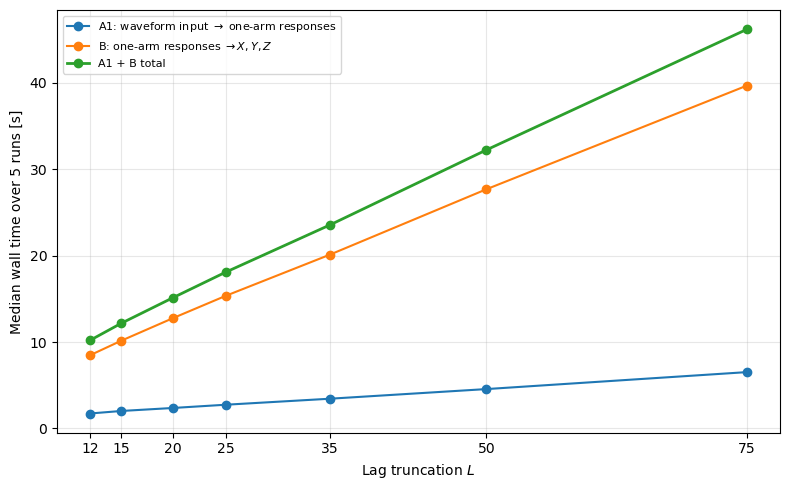

In [19]:
# -------------------------------------------------------------------
# Clean L-vs-runtime plot with linear L axis
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "df_L_runtime_summary" not in globals():
    df_L_runtime_summary = pd.read_csv(L_runtime_final_path)

df_plot = df_L_runtime_summary.copy()
df_plot = df_plot.sort_values("L_trunc").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 5))

runtime_channels = [
    (
        r"A1: waveform input $\rightarrow$ one-arm responses",
        "A1_waveform_precompute_median_s",
        {"marker": "o"},
    ),
    (
        r"B: one-arm responses $\rightarrow X,Y,Z$",
        "B_downstream_tdi_median_s",
        {"marker": "o"},
    ),
    (
        r"A1 + B total",
        "total_A1_plus_B_median_s",
        {"marker": "o", "linewidth": 2},
    ),
]

for label, col, style_kwargs in runtime_channels:
    if col not in df_plot.columns:
        print(f"Skipping {label}: column {col} not found.")
        continue

    mask = (
        np.isfinite(df_plot["L_trunc"].to_numpy(dtype=float))
        & np.isfinite(df_plot[col].to_numpy(dtype=float))
        & (df_plot["L_trunc"].to_numpy(dtype=float) > 0)
        & (df_plot[col].to_numpy(dtype=float) > 0)
    )

    d_plot = df_plot.loc[mask, ["L_trunc", col]].copy()

    if len(d_plot) == 0:
        continue

    ax.plot(
        d_plot["L_trunc"],
        d_plot[col],
        label=label,
        **style_kwargs,
    )

ax.set_xlabel(r"Lag truncation $L$")
ax.set_ylabel("Median wall time over 5 runs [s]")

ax.set_xticks(df_plot["L_trunc"].astype(int).to_numpy())
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

plot_path_pdf = FINAL_DIAG_DIR / f"L_vs_runtime_clean_Nf{Nf_final}_R2048_LB32_BC1_ip{interp_points_baseline}.pdf"
plot_path_png = FINAL_DIAG_DIR / f"L_vs_runtime_clean_Nf{Nf_final}_R2048_LB32_BC1_ip{interp_points_baseline}.png"

fig.savefig(plot_path_pdf, bbox_inches="tight")
fig.savefig(plot_path_png, dpi=300, bbox_inches="tight")

print("Saved plot to:")
print(" ", plot_path_pdf)
print(" ", plot_path_png)

plt.show()

Saved plot to:
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_runtime_clean_linear_fits_Nf100_R2048_LB32_BC1_ip16.pdf
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/L_vs_runtime_clean_linear_fits_Nf100_R2048_LB32_BC1_ip16.png


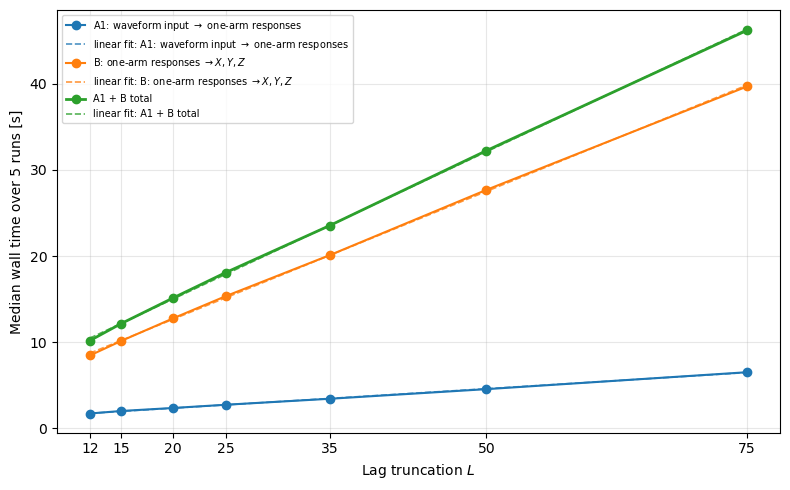

,label,slope_s_per_L,intercept_s,R2,n_points
0,A1: waveform input $\rightarrow$ one-arm respo...,0.07511,0.847453,0.999506,7
1,"B: one-arm responses $\rightarrow X,Y,Z$",0.49415,2.797339,0.999761,7
2,A1 + B total,0.56926,3.644792,0.999827,7


In [20]:
# -------------------------------------------------------------------
# Clean L-vs-runtime plot with linear L axis + linear fits
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "df_L_runtime_summary" not in globals():
    df_L_runtime_summary = pd.read_csv(L_runtime_final_path)

df_plot = df_L_runtime_summary.copy()
df_plot = df_plot.sort_values("L_trunc").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 5))

runtime_channels = [
    (
        r"A1: waveform input $\rightarrow$ one-arm responses",
        "A1_waveform_precompute_median_s",
        {"marker": "o"},
    ),
    (
        r"B: one-arm responses $\rightarrow X,Y,Z$",
        "B_downstream_tdi_median_s",
        {"marker": "o"},
    ),
    (
        r"A1 + B total",
        "total_A1_plus_B_median_s",
        {"marker": "o", "linewidth": 2},
    ),
]

fit_rows = []

for label, col, style_kwargs in runtime_channels:
    if col not in df_plot.columns:
        print(f"Skipping {label}: column {col} not found.")
        continue

    mask = (
        np.isfinite(df_plot["L_trunc"].to_numpy(dtype=float))
        & np.isfinite(df_plot[col].to_numpy(dtype=float))
        & (df_plot["L_trunc"].to_numpy(dtype=float) > 0)
        & (df_plot[col].to_numpy(dtype=float) > 0)
    )

    d_plot = df_plot.loc[mask, ["L_trunc", col]].copy()

    if len(d_plot) < 2:
        print(f"Skipping fit for {label}: not enough points.")
        continue

    x = d_plot["L_trunc"].to_numpy(dtype=float)
    y = d_plot[col].to_numpy(dtype=float)

    # -------------------------------------------------------------------
    # Linear fit: y = slope * L + intercept
    # -------------------------------------------------------------------

    slope, intercept = np.polyfit(x, y, deg=1)
    y_fit = slope * x + intercept

    residuals = y - y_fit
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    fit_rows.append(
        {
            "label": label,
            "column": col,
            "slope_s_per_L": slope,
            "intercept_s": intercept,
            "R2": r2,
            "n_points": len(x),
        }
    )

    # Measured data
    line, = ax.plot(
        x,
        y,
        label=label,
        **style_kwargs,
    )

    # Fit line, using same colour as measured series
    x_fit = np.linspace(np.min(x), np.max(x), 200)
    y_fit_smooth = slope * x_fit + intercept

    ax.plot(
        x_fit,
        y_fit_smooth,
        linestyle="--",
        linewidth=1.2,
        color=line.get_color(),
        alpha=0.8,
        label=rf"linear fit: {label}",
    )

ax.set_xlabel(r"Lag truncation $L$")
ax.set_ylabel("Median wall time over 5 runs [s]")

ax.set_xticks(df_plot["L_trunc"].astype(int).to_numpy())
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=7)

fig.tight_layout()

plot_path_pdf = FINAL_DIAG_DIR / f"L_vs_runtime_clean_linear_fits_Nf{Nf_final}_R2048_LB32_BC1_ip{interp_points_baseline}.pdf"
plot_path_png = FINAL_DIAG_DIR / f"L_vs_runtime_clean_linear_fits_Nf{Nf_final}_R2048_LB32_BC1_ip{interp_points_baseline}.png"

fig.savefig(plot_path_pdf, bbox_inches="tight")
fig.savefig(plot_path_png, dpi=300, bbox_inches="tight")

print("Saved plot to:")
print(" ", plot_path_pdf)
print(" ", plot_path_png)

plt.show()

df_L_runtime_fits = pd.DataFrame(fit_rows)

display(
    df_L_runtime_fits[
        [
            "label",
            "slope_s_per_L",
            "intercept_s",
            "R2",
            "n_points",
        ]
    ]
)

In [21]:
# -------------------------------------------------------------------
# Interpolation-points accuracy sweep setup
# -------------------------------------------------------------------

# Fixed settings for interpolation accuracy study.
# This is an accuracy-only diagnostic, not a timing benchmark.
INTERP_ACCURACY_NF = int(Nf_final)
INTERP_ACCURACY_L = int(L_baseline)

# Dense enough to show convergence, but not too many full response runs.
INTERP_POINTS_GRID = [2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64]

interp_accuracy_partial_path = (
    FINAL_DIAG_DIR
    / f"interp_points_vs_mismatch_Nf{INTERP_ACCURACY_NF}_L{INTERP_ACCURACY_L}_partial.csv"
)

interp_accuracy_final_path = (
    FINAL_DIAG_DIR
    / f"interp_points_vs_mismatch_Nf{INTERP_ACCURACY_NF}_L{INTERP_ACCURACY_L}_full.csv"
)

print("Interpolation-points accuracy sweep:")
print("  Nf:                 ", INTERP_ACCURACY_NF)
print("  DeltaT:             ", INTERP_ACCURACY_NF * dt)
print("  L:                  ", INTERP_ACCURACY_L)
print("  n_lags:             ", 2 * INTERP_ACCURACY_L + 1)
print("  interpolation grid: ", INTERP_POINTS_GRID)
print()
print("Output paths:")
print("  partial:", interp_accuracy_partial_path)
print("  final:  ", interp_accuracy_final_path)

Interpolation-points accuracy sweep:
  Nf:                  100
  DeltaT:              1000.0
  L:                   25
  n_lags:              51
  interpolation grid:  [2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64]

Output paths:
  partial: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/interp_points_vs_mismatch_Nf100_L25_partial.csv
  final:   runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/interp_points_vs_mismatch_Nf100_L25_full.csv


In [22]:
# -------------------------------------------------------------------
# Run interpolation-points accuracy sweep
# -------------------------------------------------------------------

if "run_final_accuracy_case" not in globals():
    raise NameError("run_final_accuracy_case is not defined. Run the accuracy helper cell first.")

# Fresh run
for path in [interp_accuracy_partial_path, interp_accuracy_final_path]:
    if path.exists():
        path.unlink()
        print("Removed old file:", path)

interp_accuracy_results = []

for interp_points in INTERP_POINTS_GRID:
    interp_points = int(interp_points)

    print()
    print("#" * 100)
    print(
        f"Interpolation accuracy case: "
        f"Nf={INTERP_ACCURACY_NF}, "
        f"L={INTERP_ACCURACY_L}, "
        f"interp_points={interp_points}"
    )
    print("#" * 100)

    row = run_final_accuracy_case(
        Nf_value=INTERP_ACCURACY_NF,
        L_value=INTERP_ACCURACY_L,
        interp_points=interp_points,
        d_value=d,
        A_frac_value=A_frac,
    )

    # Add reproducibility information about the shift/backend settings.
    shift_kwargs = make_variable_shift_kwargs(interp_points=interp_points)

    row["assembly_backend"] = shift_kwargs.get("assembly_backend", "")
    row["assembly_precision"] = shift_kwargs.get("assembly_precision", "")
    row["row_chunk_size"] = shift_kwargs.get("row_chunk_size", np.nan)
    row["lag_block_size"] = shift_kwargs.get("lag_block_size", np.nan)
    row["batch_chunk"] = shift_kwargs.get("batch_chunk", np.nan)
    row["tl_tp_mode"] = shift_kwargs.get("tl_tp_mode", "")
    row["tl_tp_interp_kind"] = shift_kwargs.get("tl_tp_interp_kind", "")
    row["tl_tp_interp_backend"] = shift_kwargs.get("tl_tp_interp_backend", "")
    row["calc_m0"] = bool(CALC_M0)

    interp_accuracy_results.append(row)

    df_interp_accuracy = pd.DataFrame(interp_accuracy_results)
    df_interp_accuracy = df_interp_accuracy.sort_values("interp_points").reset_index(drop=True)
    df_interp_accuracy.to_csv(interp_accuracy_partial_path, index=False)

    print("Saved partial interpolation accuracy results to:", interp_accuracy_partial_path)

df_interp_accuracy = pd.DataFrame(interp_accuracy_results)
df_interp_accuracy = df_interp_accuracy.sort_values("interp_points").reset_index(drop=True)
df_interp_accuracy.to_csv(interp_accuracy_final_path, index=False)

print()
print("Saved final interpolation accuracy results to:", interp_accuracy_final_path)

display(
    df_interp_accuracy[
        [
            "Nf",
            "DeltaT",
            "L_trunc",
            "interp_points",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
            "max_mismatch_cut",
            "assembly_backend",
            "row_chunk_size",
            "lag_block_size",
            "batch_chunk",
        ]
    ]
)


####################################################################################################
Interpolation accuracy case: Nf=100, L=25, interp_points=2
####################################################################################################

Accuracy case: Nf=100, L=25, interp_points=2, d=4, A_frac=0.25
X mismatch:        0.0007917651369323733
Y mismatch:        0.0017307651668065555
Z mismatch:        0.001245326750346357
link 12 mismatch:  0.001982941381539435
max mismatch:      0.001982941381539435
Saved partial interpolation accuracy results to: runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/interp_points_vs_mismatch_Nf100_L25_partial.csv

####################################################################################################
Interpolation accuracy case: Nf=100, L=25, interp_points=3
####################################################################################################

Accuracy case: Nf=100, L=25, inter

,Nf,DeltaT,L_trunc,interp_points,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut,max_mismatch_cut,assembly_backend,row_chunk_size,lag_block_size,batch_chunk
0,100,1000.0,25,2,0.000792,0.001731,0.001245,0.001983,0.001983,lagfirst_chunked_lagblock,2048,32,1
1,100,1000.0,25,3,0.000097,0.000137,0.000099,0.000178,0.000178,lagfirst_chunked_lagblock,2048,32,1
2,100,1000.0,25,4,0.000022,0.000029,0.000024,0.000035,0.000035,lagfirst_chunked_lagblock,2048,32,1
3,100,1000.0,25,6,0.000004,0.000006,0.000005,0.000005,0.000006,lagfirst_chunked_lagblock,2048,32,1
4,100,1000.0,25,8,0.000002,0.000003,0.000002,0.000002,0.000003,lagfirst_chunked_lagblock,2048,32,1
5,100,1000.0,25,12,0.000001,0.000002,0.000002,0.000001,0.000002,lagfirst_chunked_lagblock,2048,32,1
6,100,1000.0,25,16,0.000001,0.000002,0.000002,0.000001,0.000002,lagfirst_chunked_lagblock,2048,32,1
7,100,1000.0,25,24,0.000001,0.000002,0.000002,0.000001,0.000002,lagfirst_chunked_lagblock,2048,32,1
8,100,1000.0,25,32,0.000001,0.000002,0.000002,0.000001,0.000002,lagfirst_chunked_lagblock,2048,32,1
9,100,1000.0,25,48,0.000001,0.000002,0.000002,0.000001,0.000002,lagfirst_chunked_lagblock,2048,32,1


Saved interpolation accuracy plot to:
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/interp_points_vs_mismatch_Nf100_L25.pdf
  runs/emri_1yr_td_Nf500_dt10/deltaT_sensitivity_1yr/final_L_interp_diagnostics/interp_points_vs_mismatch_Nf100_L25.png


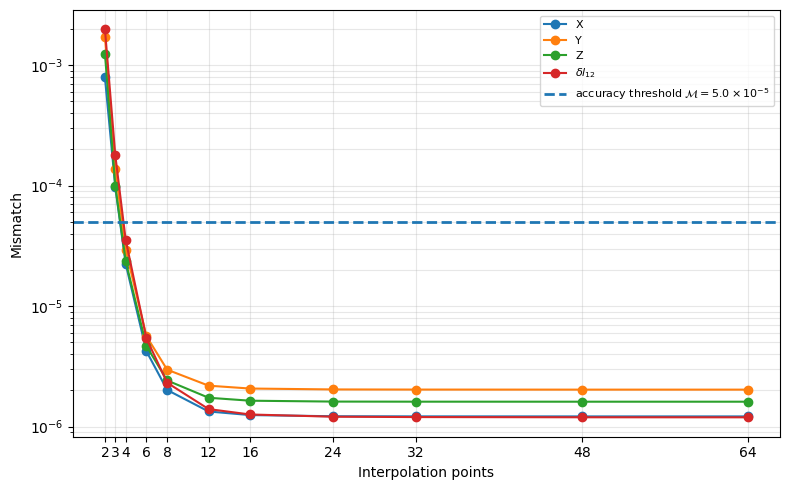

In [25]:
# -------------------------------------------------------------------
# Plot interpolation points versus mismatch
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "df_interp_accuracy" not in globals():
    if interp_accuracy_final_path.exists():
        df_interp_accuracy = pd.read_csv(interp_accuracy_final_path)
    else:
        raise NameError(
            "df_interp_accuracy is not defined and the interpolation accuracy CSV was not found."
        )

dfp = df_interp_accuracy.copy()
dfp = dfp.sort_values("interp_points").reset_index(drop=True)

# Same mismatch cutoff used elsewhere
MISMATCH_CUTOFF = float(globals().get("MISMATCH_TIMING_THRESHOLD", 5e-5))

fig, ax = plt.subplots(figsize=(8, 5))

channels = [
    ("X", "X_mismatch_cut", {"marker": "o"}),
    ("Y", "Y_mismatch_cut", {"marker": "o"}),
    ("Z", "Z_mismatch_cut", {"marker": "o"}),
    (r"$\delta l_{12}$", "link_12_mismatch_cut", {"marker": "o"}),
]

for label, col, style_kwargs in channels:
    if col not in dfp.columns:
        print(f"Skipping {label}: column {col} not found.")
        continue

    mask = (
        np.isfinite(dfp["interp_points"].to_numpy(dtype=float))
        & np.isfinite(dfp[col].to_numpy(dtype=float))
        & (dfp["interp_points"].to_numpy(dtype=float) > 0)
        & (dfp[col].to_numpy(dtype=float) > 0)
    )

    d_plot = dfp.loc[mask, ["interp_points", col]].copy()

    if len(d_plot) == 0:
        continue

    ax.semilogy(
        d_plot["interp_points"],
        d_plot[col],
        label=label,
        **style_kwargs,
    )

# -------------------------------------------------------------------
# Accuracy threshold line
# -------------------------------------------------------------------

ax.axhline(
    MISMATCH_TIMING_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=r"accuracy threshold $\mathcal{{M}}={5.0 \times 10^{-5} }$",
)


ax.set_xlabel("Interpolation points")
ax.set_ylabel("Mismatch")

ax.set_xticks(dfp["interp_points"].astype(int).to_numpy())
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

interp_accuracy_plot_path_pdf = (
    FINAL_DIAG_DIR
    / f"interp_points_vs_mismatch_Nf{INTERP_ACCURACY_NF}_L{INTERP_ACCURACY_L}.pdf"
)

interp_accuracy_plot_path_png = (
    FINAL_DIAG_DIR
    / f"interp_points_vs_mismatch_Nf{INTERP_ACCURACY_NF}_L{INTERP_ACCURACY_L}.png"
)

fig.savefig(interp_accuracy_plot_path_pdf, bbox_inches="tight")
fig.savefig(interp_accuracy_plot_path_png, dpi=300, bbox_inches="tight")

print("Saved interpolation accuracy plot to:")
print(" ", interp_accuracy_plot_path_pdf)
print(" ", interp_accuracy_plot_path_png)

plt.show()